In [1]:
import sys
import importlib.util
from pathlib import Path

def find_project_root(start_path=None):
    if start_path is None:
        start_path = Path.cwd()
    else:
        start_path = Path(start_path)

    current = start_path.resolve()

    while True:
        if (current / "09_config.py").exists() and (current / "08_utils.py").exists():
            return current

        if current.parent == current:
            raise FileNotFoundError("Project root tidak ditemukan. Pastikan 09_config.py dan 08_utils.py ada.")

        current = current.parent

def import_py_file(module_name, file_path):
    file_path = Path(file_path).resolve()
    spec = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

PROJECT_ROOT = find_project_root()
print("PROJECT_ROOT:", PROJECT_ROOT)

cfg = import_py_file("ferplus_config", PROJECT_ROOT / "09_config.py")
utils = import_py_file("ferplus_utils", PROJECT_ROOT / "08_utils.py")

utils.set_global_seed(cfg.SEED)
utils.ensure_directories()

print("Dataset root:", cfg.DATASET_DIR)
print("Folder yang akan dicek:")
for split_name, split_dir in cfg.DATASET_SPLITS_TO_CHECK.items():
    print(split_name, "->", split_dir)

PROJECT_ROOT: C:\Users\Davin\Downloads\Skripsi\project_skripsi
TensorFlow op determinism: ENABLED
Dataset root: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset
Folder yang akan dicek:
training_full -> C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_full
training_non_augmented -> C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_non_augmented
validation_full -> C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\validation_full
validation_non_augmented -> C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\validation_non_augmented
test -> C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test


In [2]:
from pathlib import Path

folder_status_rows = []

for split_name, split_dir in cfg.DATASET_SPLITS_TO_CHECK.items():
    split_dir = Path(split_dir)

    status = split_dir.exists()

    folder_status_rows.append({
        "split": split_name,
        "path": str(split_dir),
        "exists": status
    })

    print(f"{split_name:28s} | {split_dir} | exists={status}")

folder_status_df = __import__("pandas").DataFrame(folder_status_rows)
display(folder_status_df)

folder_status_path = cfg.RESULT_DIR / "dataset_folder_status.csv"
folder_status_df.to_csv(folder_status_path, index=False)

print("Status folder disimpan ke:", folder_status_path)

training_full                | C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_full | exists=True
training_non_augmented       | C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_non_augmented | exists=True
validation_full              | C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\validation_full | exists=True
validation_non_augmented     | C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\validation_non_augmented | exists=True
test                         | C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test | exists=True


,split,path,exists
0,training_full,C:\Users\Davin\Downloads\Skripsi\project_skrip...,True
1,training_non_augmented,C:\Users\Davin\Downloads\Skripsi\project_skrip...,True
2,validation_full,C:\Users\Davin\Downloads\Skripsi\project_skrip...,True
3,validation_non_augmented,C:\Users\Davin\Downloads\Skripsi\project_skrip...,True
4,test,C:\Users\Davin\Downloads\Skripsi\project_skrip...,True


Status folder disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\dataset_folder_status.csv


In [3]:
import pandas as pd

class_folder_rows = []

for split_name, split_dir in cfg.DATASET_SPLITS_TO_CHECK.items():
    split_dir = Path(split_dir)

    if not split_dir.exists():
        continue

    found_classes = sorted([p.name for p in split_dir.iterdir() if p.is_dir()])

    missing_classes = sorted(list(set(cfg.CLASS_NAMES) - set(found_classes)))
    extra_classes = sorted(list(set(found_classes) - set(cfg.CLASS_NAMES)))

    class_folder_rows.append({
        "split": split_name,
        "found_classes": ", ".join(found_classes),
        "missing_classes": ", ".join(missing_classes),
        "extra_classes": ", ".join(extra_classes),
        "is_valid_class_structure": len(missing_classes) == 0 and len(extra_classes) == 0
    })

class_folder_df = pd.DataFrame(class_folder_rows)
display(class_folder_df)

class_folder_path = cfg.RESULT_DIR / "dataset_class_folder_check.csv"
class_folder_df.to_csv(class_folder_path, index=False)

print("Cek folder kelas disimpan ke:", class_folder_path)

,split,found_classes,missing_classes,extra_classes,is_valid_class_structure
0,training_full,"angry, contempt, disgust, fear, happy, neutral...",,,True
1,training_non_augmented,"angry, contempt, disgust, fear, happy, neutral...",,,True
2,validation_full,"angry, contempt, disgust, fear, happy, neutral...",,,True
3,validation_non_augmented,"angry, contempt, disgust, fear, happy, neutral...",,,True
4,test,"angry, contempt, disgust, fear, happy, neutral...",,,True


Cek folder kelas disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\dataset_class_folder_check.csv


In [4]:
all_count_dfs = []
all_detail_dfs = []

for split_name, split_dir in cfg.DATASET_SPLITS_TO_CHECK.items():
    df_count, df_detail = utils.check_dataset_split(
        split_name=split_name,
        split_dir=split_dir,
        check_corrupt=True,
        compute_hash=True,
        compute_phash=True
    )

    all_count_dfs.append(df_count)
    all_detail_dfs.append(df_detail)

df_count_all = pd.concat(all_count_dfs, ignore_index=True)
df_detail_all = pd.concat(all_detail_dfs, ignore_index=True)

display(df_count_all)

count_path = cfg.RESULT_DIR / "dataset_count_summary.csv"
detail_path = cfg.RESULT_DIR / "dataset_detail_check.csv"

df_count_all.to_csv(count_path, index=False)
df_detail_all.to_csv(detail_path, index=False)

print("Ringkasan jumlah dataset disimpan ke:", count_path)
print("Detail pengecekan dataset disimpan ke:", detail_path)


CEK DATASET SPLIT: training_full
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_full
Kelas ditemukan: ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
angry      | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:    5524
contempt   | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:    7830
disgust    | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:    7805
fear       | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:    7341
happy      | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:     463
neutral    | total:   10379 | valid:   10379 | corrupt:    0 | augmented-name:       0
sad        | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:    4441
surprise   | total:    8000 | valid:    8000 | corrupt:    0 | augmented-name:    4417

CEK DATASET SPLIT: training_non_augmented
Path: C:\Users\Davin\Downloads\Skripsi\project_skrips

,split,class,total_files,valid_images,corrupt_images,augmented_filename_count,percentage_in_split,unique_widths,unique_heights,unique_modes,unique_extensions,is_empty_class
0,training_full,angry,8000,8000,0,5524,12.052004,[112],[112],[L],[.png],False
1,training_full,contempt,8000,8000,0,7830,12.052004,[112],[112],[L],[.png],False
2,training_full,disgust,8000,8000,0,7805,12.052004,[112],[112],[L],[.png],False
3,training_full,fear,8000,8000,0,7341,12.052004,[112],[112],[L],[.png],False
4,training_full,happy,8000,8000,0,463,12.052004,[112],[112],[L],[.png],False
5,training_full,neutral,10379,10379,0,0,15.635969,[112],[112],[L],[.png],False
6,training_full,sad,8000,8000,0,4441,12.052004,[112],[112],[L],[.png],False
7,training_full,surprise,8000,8000,0,4417,12.052004,[112],[112],[L],[.png],False
8,training_non_augmented,angry,2476,2476,0,0,8.670075,[112],[112],[L],[.png],False
9,training_non_augmented,contempt,170,170,0,0,0.595280,[112],[112],[L],[.png],False


Ringkasan jumlah dataset disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\dataset_count_summary.csv
Detail pengecekan dataset disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\dataset_detail_check.csv


In [15]:
must_be_zero_augmented = [
    "training_non_augmented",
    "validation_non_augmented",
    "test"
]

augmented_warning_df = df_detail_all[
    (df_detail_all["split"].isin(must_be_zero_augmented)) &
    (df_detail_all["is_augmented_filename"] == True)
].copy()

augmented_count_summary = (
    df_detail_all
    .groupby(["split", "class"])["is_augmented_filename"]
    .sum()
    .reset_index(name="augmented_filename_count")
)

display(augmented_count_summary)

augmented_count_path = cfg.RESULT_DIR / "augmented_filename_count_per_split_class.csv"
augmented_count_summary.to_csv(augmented_count_path, index=False)

print("Jumlah file augmented per split-kelas disimpan ke:", augmented_count_path)

if len(augmented_warning_df) > 0:
    print("PERINGATAN: Masih ada file bernama/mengandung 'augmented' pada folder yang seharusnya sudah bersih.")
    display(augmented_warning_df[["split", "class", "filename", "path"]])

    warning_path = cfg.RESULT_DIR / "warning_augmented_files_still_found.csv"
    augmented_warning_df.to_csv(warning_path, index=False)

    print("Daftar file bermasalah disimpan ke:", warning_path)
else:
    print("AMAN: training_non_augmented, validation_non_augmented, dan test tidak mengandung file augmented.")

,split,class,augmented_filename_count
0,test,angry,0
1,test,contempt,0
2,test,disgust,0
3,test,fear,0
4,test,happy,0
5,test,neutral,0
6,test,sad,0
7,test,surprise,0
8,training_full,angry,5524
9,training_full,contempt,7830


Jumlah file augmented per split-kelas disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\augmented_filename_count_per_split_class.csv
AMAN: training_non_augmented, validation_non_augmented, dan test tidak mengandung file augmented.


In [5]:
train_compare_df = utils.compare_full_vs_non_augmented(
    df_count=df_count_all,
    full_split="training_full",
    non_aug_split="training_non_augmented"
)

val_compare_df = utils.compare_full_vs_non_augmented(
    df_count=df_count_all,
    full_split="validation_full",
    non_aug_split="validation_non_augmented"
)

print("Perbandingan training_full vs training_non_augmented")
display(train_compare_df)

print("Perbandingan validation_full vs validation_non_augmented")
display(val_compare_df)

train_compare_path = cfg.RESULT_DIR / "comparison_training_full_vs_non_augmented.csv"
val_compare_path = cfg.RESULT_DIR / "comparison_validation_full_vs_non_augmented.csv"

train_compare_df.to_csv(train_compare_path, index=False)
val_compare_df.to_csv(val_compare_path, index=False)

print("Perbandingan training disimpan ke:", train_compare_path)
print("Perbandingan validation disimpan ke:", val_compare_path)

Perbandingan training_full vs training_non_augmented


,class,training_full_count,training_non_augmented_count,removed_or_difference,remaining_percentage
0,angry,8000,2476,5524,30.9500
1,contempt,8000,170,7830,2.1250
2,disgust,8000,195,7805,2.4375
3,fear,8000,659,7341,8.2375
4,happy,8000,7537,463,94.2125
5,neutral,10379,10379,0,100.0000
6,sad,8000,3559,4441,44.4875
7,surprise,8000,3583,4417,44.7875


Perbandingan validation_full vs validation_non_augmented


,class,validation_full_count,validation_non_augmented_count,removed_or_difference,remaining_percentage
0,angry,1000,326,674,32.6
1,contempt,1000,27,973,2.7
2,disgust,1000,34,966,3.4
3,fear,1000,72,928,7.2
4,happy,1000,899,101,89.9
5,neutral,1341,1341,0,100.0
6,sad,1000,419,581,41.9
7,surprise,1000,461,539,46.1


Perbandingan training disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\comparison_training_full_vs_non_augmented.csv
Perbandingan validation disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\comparison_validation_full_vs_non_augmented.csv


In [6]:
imbalance_summary = utils.summarize_imbalance(
    df_count=df_count_all,
    split_name="training_non_augmented"
)

print("Ringkasan ketidakseimbangan training_non_augmented:")
for key, value in imbalance_summary.items():
    print(f"{key}: {value}")

imbalance_path = cfg.RESULT_DIR / "imbalance_summary_training_non_augmented.json"
utils.save_json(imbalance_summary, imbalance_path)

print("Ringkasan imbalance disimpan ke:", imbalance_path)

train_non_aug_df = df_count_all[df_count_all["split"] == "training_non_augmented"].copy()
train_non_aug_df = train_non_aug_df[["class", "valid_images", "percentage_in_split"]]

display(train_non_aug_df)

Ringkasan ketidakseimbangan training_non_augmented:
split: training_non_augmented
total_images: 28558
max_class: neutral
max_class_count: 10379
min_class: contempt
min_class_count: 170
imbalance_ratio_max_min: 61.05294117647059
Ringkasan imbalance disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\imbalance_summary_training_non_augmented.json


,class,valid_images,percentage_in_split
8,angry,2476,8.670075
9,contempt,170,0.595280
10,disgust,195,0.682821
11,fear,659,2.307585
12,happy,7537,26.391904
13,neutral,10379,36.343581
14,sad,3559,12.462357
15,surprise,3583,12.546397


In [7]:
empty_class_df = df_count_all[df_count_all["is_empty_class"] == True].copy()

if len(empty_class_df) > 0:
    print("PERINGATAN: Ada kelas kosong.")
    display(empty_class_df)

    empty_class_path = cfg.RESULT_DIR / "warning_empty_classes.csv"
    empty_class_df.to_csv(empty_class_path, index=False)

    print("Daftar kelas kosong disimpan ke:", empty_class_path)
else:
    print("AMAN: Tidak ada kelas kosong pada seluruh split.")

AMAN: Tidak ada kelas kosong pada seluruh split.


In [8]:
corrupt_df = df_detail_all[df_detail_all["is_valid"] == False].copy()

if len(corrupt_df) > 0:
    print("PERINGATAN: Ada file gambar rusak.")
    display(corrupt_df[["split", "class", "filename", "path", "error"]])

    corrupt_path = cfg.RESULT_DIR / "warning_corrupt_images.csv"
    corrupt_df.to_csv(corrupt_path, index=False)

    print("Daftar file rusak disimpan ke:", corrupt_path)
else:
    print("AMAN: Tidak ditemukan file gambar rusak.")

AMAN: Tidak ditemukan file gambar rusak.


In [9]:
valid_detail_df = df_detail_all[df_detail_all["is_valid"] == True].copy()

size_distribution = (
    valid_detail_df
    .groupby(["split", "width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "count"], ascending=[True, False])
)

mode_distribution = (
    valid_detail_df
    .groupby(["split", "mode"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "count"], ascending=[True, False])
)

extension_distribution = (
    valid_detail_df
    .groupby(["split", "extension"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "count"], ascending=[True, False])
)

print("Distribusi ukuran gambar:")
display(size_distribution)

print("Distribusi mode/channel gambar:")
display(mode_distribution)

print("Distribusi ekstensi gambar:")
display(extension_distribution)

size_path = cfg.RESULT_DIR / "image_size_distribution.csv"
mode_path = cfg.RESULT_DIR / "image_mode_distribution.csv"
extension_path = cfg.RESULT_DIR / "image_extension_distribution.csv"

size_distribution.to_csv(size_path, index=False)
mode_distribution.to_csv(mode_path, index=False)
extension_distribution.to_csv(extension_path, index=False)

print("Distribusi ukuran disimpan ke:", size_path)
print("Distribusi mode disimpan ke:", mode_path)
print("Distribusi ekstensi disimpan ke:", extension_path)

Distribusi ukuran gambar:


,split,width,height,count
0,test,112,112,3573
1,training_full,112,112,66379
2,training_non_augmented,112,112,28558
3,validation_full,112,112,8341
4,validation_non_augmented,112,112,3579


Distribusi mode/channel gambar:


,split,mode,count
0,test,L,3573
1,training_full,L,66379
2,training_non_augmented,L,28558
3,validation_full,L,8341
4,validation_non_augmented,L,3579


Distribusi ekstensi gambar:


,split,extension,count
0,test,.png,3573
1,training_full,.png,66379
2,training_non_augmented,.png,28558
3,validation_full,.png,8341
4,validation_non_augmented,.png,3579


Distribusi ukuran disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\image_size_distribution.csv
Distribusi mode disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\image_mode_distribution.csv
Distribusi ekstensi disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\image_extension_distribution.csv


In [16]:
active_splits = [
    "training_full",
    "training_non_augmented",
    "validation_non_augmented",
    "test"
]

df_detail_active = df_detail_all[df_detail_all["split"].isin(active_splits)].copy()

exact_duplicates_df = utils.find_exact_duplicates(df_detail_active)

def has_split(split_text, target_splits):
    split_set = set([s.strip() for s in str(split_text).split(",")])
    return len(split_set.intersection(target_splits)) > 0

train_splits = {"training_full", "training_non_augmented"}
val_splits = {"validation_non_augmented"}
test_splits = {"test"}

if exact_duplicates_df.empty:
    summary_duplicate_df = pd.DataFrame({
        "Jenis Duplicate": [
            "Duplicate antar kelas",
            "Duplicate train-validation",
            "Duplicate train-test",
            "Duplicate validation-test",
            "Duplicate internal test"
        ],
        "Jumlah Grup": [0, 0, 0, 0, 0]
    })
else:
    duplicate_antar_kelas = exact_duplicates_df[
        exact_duplicates_df["is_duplicate_across_classes"] == True
    ]

    duplicate_train_validation = exact_duplicates_df[
        exact_duplicates_df["splits"].apply(lambda x: has_split(x, train_splits)) &
        exact_duplicates_df["splits"].apply(lambda x: has_split(x, val_splits))
    ]

    duplicate_train_test = exact_duplicates_df[
        exact_duplicates_df["splits"].apply(lambda x: has_split(x, train_splits)) &
        exact_duplicates_df["splits"].apply(lambda x: has_split(x, test_splits))
    ]

    duplicate_validation_test = exact_duplicates_df[
        exact_duplicates_df["splits"].apply(lambda x: has_split(x, val_splits)) &
        exact_duplicates_df["splits"].apply(lambda x: has_split(x, test_splits))
    ]

    duplicate_internal_test = exact_duplicates_df[
        exact_duplicates_df["splits"].astype(str).str.strip() == "test"
    ]

    summary_duplicate_df = pd.DataFrame({
        "Jenis Duplicate": [
            "Duplicate antar kelas",
            "Duplicate train-validation",
            "Duplicate train-test",
            "Duplicate validation-test",
            "Duplicate internal test"
        ],
        "Jumlah Grup": [
            len(duplicate_antar_kelas),
            len(duplicate_train_validation),
            len(duplicate_train_test),
            len(duplicate_validation_test),
            len(duplicate_internal_test)
        ]
    })

display(summary_duplicate_df)

summary_path = cfg.RESULT_DIR / "ringkasan_exact_duplicate_md5.csv"
summary_duplicate_df.to_csv(summary_path, index=False, encoding="utf-8-sig")

print("\nRingkasan disimpan ke:")
print(summary_path)

,Jenis Duplicate,Jumlah Grup
0,Duplicate antar kelas,242
1,Duplicate train-validation,269
2,Duplicate train-test,278
3,Duplicate validation-test,43
4,Duplicate internal test,7



Ringkasan disimpan ke:
C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\ringkasan_exact_duplicate_md5.csv


In [17]:
active_splits = [
    "training_full",
    "training_non_augmented",
    "validation_non_augmented",
    "test"
]

df_detail_active = df_detail_all[df_detail_all["split"].isin(active_splits)].copy()

df_detail_active["is_valid"] = df_detail_active["is_valid"].astype(str).str.lower().eq("true")

near_duplicate_df = utils.find_near_duplicates_by_phash(
    df_detail_active,
    max_hamming_distance=3,
    max_pairs=50000
)

def has_split(split_text, target_splits):
    split_set = set([s.strip() for s in str(split_text).replace("|", ",").split(",")])
    return len(split_set.intersection(target_splits)) > 0

def only_test(split_text):
    split_set = set([s.strip() for s in str(split_text).replace("|", ",").split(",")])
    return split_set == {"test"}

train_splits = {"training_full", "training_non_augmented"}
val_splits = {"validation_non_augmented"}
test_splits = {"test"}

if near_duplicate_df.empty:
    summary_near_duplicate_df = pd.DataFrame({
        "Jenis Near Duplicate": [
            "Near duplicate antar kelas",
            "Near duplicate train-validation",
            "Near duplicate train-test",
            "Near duplicate validation-test",
            "Near duplicate internal test"
        ],
        "Jumlah Grup/Pasangan": [0, 0, 0, 0, 0]
    })
else:
    near_duplicate_antar_kelas = near_duplicate_df[
        near_duplicate_df["classes"].astype(str).str.contains(",|\\|", regex=True)
    ]

    near_duplicate_train_validation = near_duplicate_df[
        near_duplicate_df["splits"].apply(lambda x: has_split(x, train_splits)) &
        near_duplicate_df["splits"].apply(lambda x: has_split(x, val_splits))
    ]

    near_duplicate_train_test = near_duplicate_df[
        near_duplicate_df["splits"].apply(lambda x: has_split(x, train_splits)) &
        near_duplicate_df["splits"].apply(lambda x: has_split(x, test_splits))
    ]

    near_duplicate_validation_test = near_duplicate_df[
        near_duplicate_df["splits"].apply(lambda x: has_split(x, val_splits)) &
        near_duplicate_df["splits"].apply(lambda x: has_split(x, test_splits))
    ]

    near_duplicate_internal_test = near_duplicate_df[
        near_duplicate_df["splits"].apply(only_test)
    ]

    summary_near_duplicate_df = pd.DataFrame({
        "Jenis Near Duplicate": [
            "Near duplicate antar kelas",
            "Near duplicate train-validation",
            "Near duplicate train-test",
            "Near duplicate validation-test",
            "Near duplicate internal test"
        ],
        "Jumlah Grup/Pasangan": [
            len(near_duplicate_antar_kelas),
            len(near_duplicate_train_validation),
            len(near_duplicate_train_test),
            len(near_duplicate_validation_test),
            len(near_duplicate_internal_test)
        ]
    })

display(summary_near_duplicate_df)

summary_path = cfg.RESULT_DIR / "ringkasan_near_duplicate_phash.csv"
summary_near_duplicate_df.to_csv(summary_path, index=False, encoding="utf-8-sig")

print("\nRingkasan near duplicate disimpan ke:")
print(summary_path)

,Jenis Near Duplicate,Jumlah Grup/Pasangan
0,Near duplicate antar kelas,316
1,Near duplicate train-validation,289
2,Near duplicate train-test,291
3,Near duplicate validation-test,49
4,Near duplicate internal test,6



Ringkasan near duplicate disimpan ke:
C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\ringkasan_near_duplicate_phash.csv


split,test,training_full,training_non_augmented,validation_full,validation_non_augmented
class,,,,,
angry,322,8000,2476,1000,326
contempt,30,8000,170,1000,27
disgust,21,8000,195,1000,34
fear,98,8000,659,1000,72
happy,929,8000,7537,1000,899
neutral,1274,10379,10379,1341,1341
sad,449,8000,3559,1000,419
surprise,450,8000,3583,1000,461


<Figure size 1400x700 with 0 Axes>

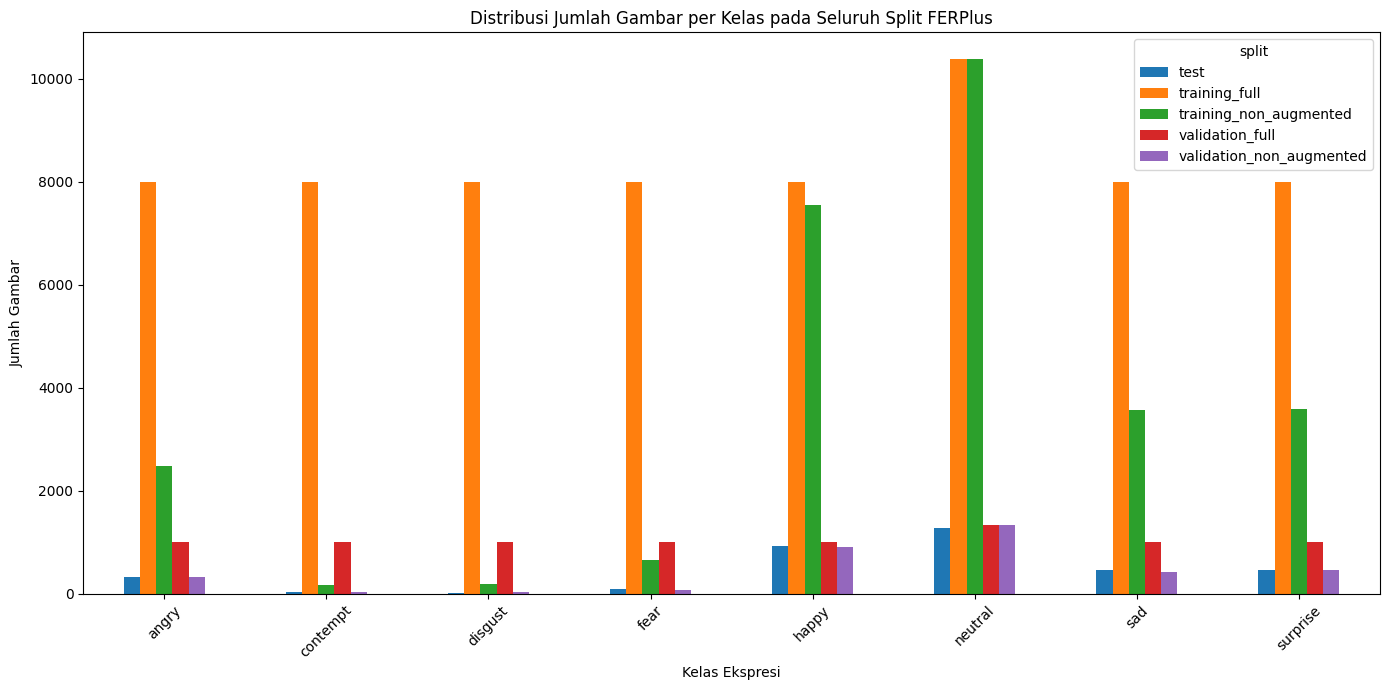

Grafik distribusi semua split disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\dataset_distribution_all_splits.png


In [18]:
import matplotlib.pyplot as plt

pivot_distribution = df_count_all.pivot(
    index="class",
    columns="split",
    values="valid_images"
)

display(pivot_distribution)

plt.figure(figsize=(14, 7))
pivot_distribution.plot(kind="bar", figsize=(14, 7))

plt.title("Distribusi Jumlah Gambar per Kelas pada Seluruh Split FERPlus")
plt.xlabel("Kelas Ekspresi")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.tight_layout()

save_path = cfg.FIGURE_DIR / "dataset_distribution_all_splits.png"
plt.savefig(save_path, dpi=300)
plt.show()

print("Grafik distribusi semua split disimpan ke:", save_path)

<Figure size 1200x600 with 0 Axes>

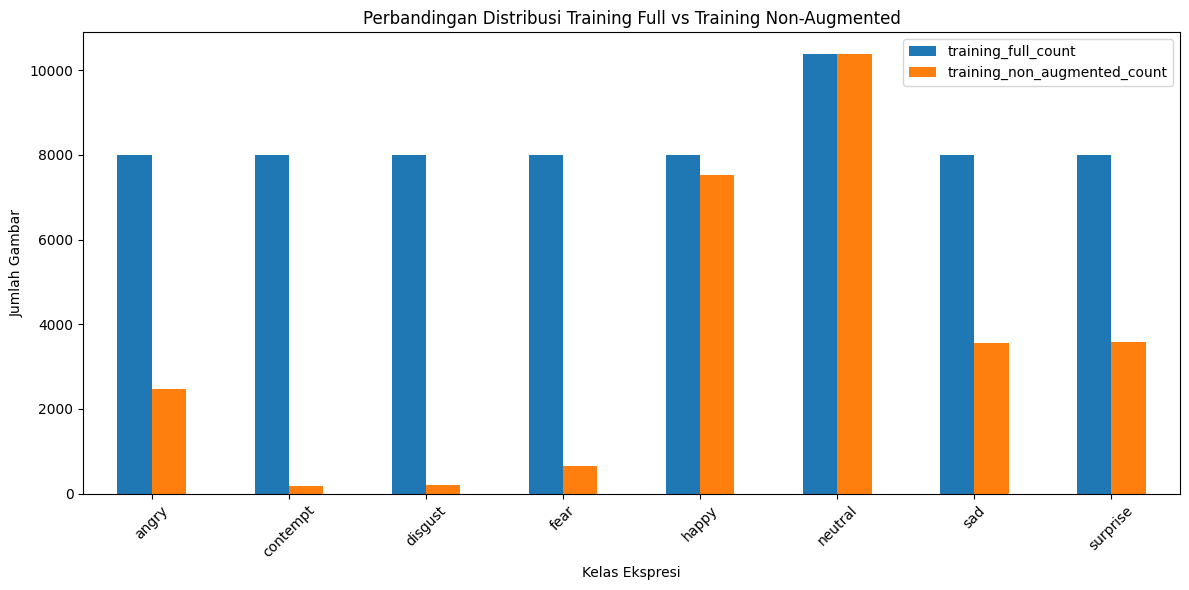

Grafik perbandingan training disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_training_full_vs_non_augmented.png


In [19]:
plot_df = train_compare_df.set_index("class")[
    ["training_full_count", "training_non_augmented_count"]
]

plt.figure(figsize=(12, 6))
plot_df.plot(kind="bar", figsize=(12, 6))

plt.title("Perbandingan Distribusi Training Full vs Training Non-Augmented")
plt.xlabel("Kelas Ekspresi")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.tight_layout()

save_path = cfg.FIGURE_DIR / "comparison_training_full_vs_non_augmented.png"
plt.savefig(save_path, dpi=300)
plt.show()

print("Grafik perbandingan training disimpan ke:", save_path)

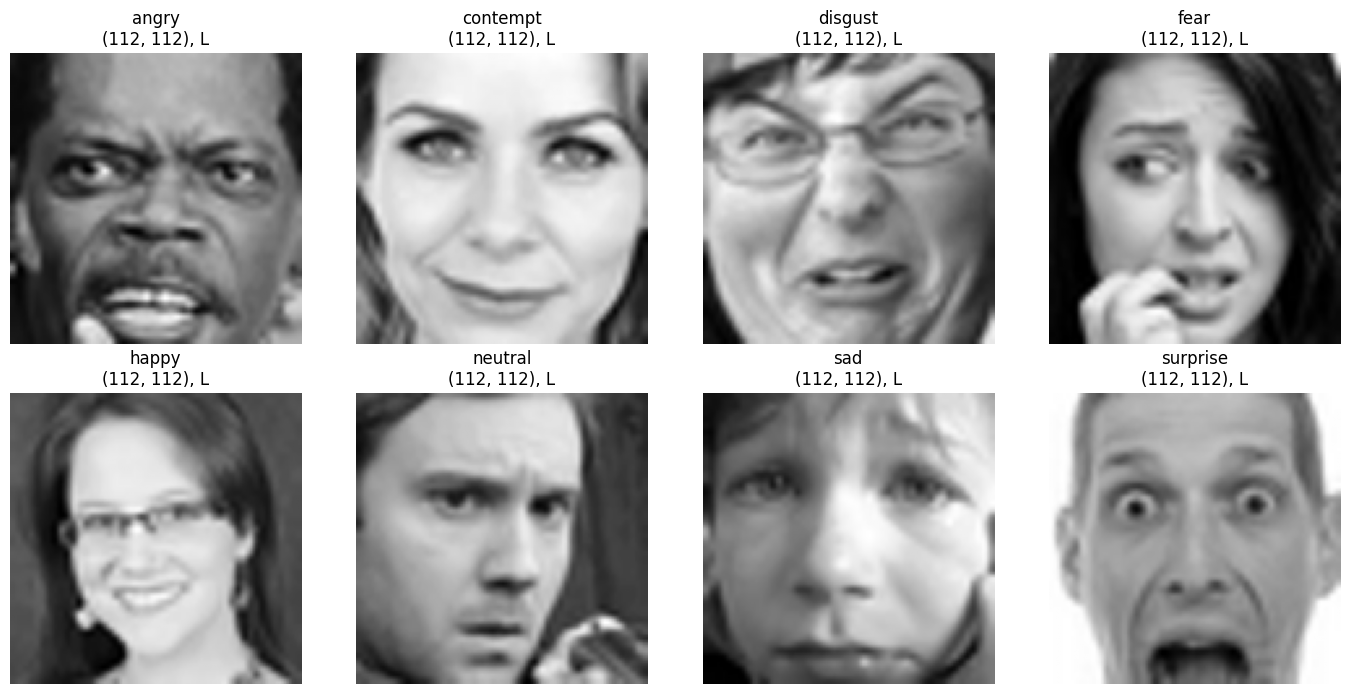

Contoh gambar disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\sample_images_training_non_augmented.png


,split,class,path,size,mode
0,training_non_augmented,angry,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
1,training_non_augmented,contempt,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
2,training_non_augmented,disgust,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
3,training_non_augmented,fear,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
4,training_non_augmented,happy,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
5,training_non_augmented,neutral,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
6,training_non_augmented,sad,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L
7,training_non_augmented,surprise,C:\Users\Davin\Downloads\Skripsi\project_skrip...,"(112, 112)",L


In [20]:
from PIL import Image

def show_sample_images(split_name, split_dir):
    plt.figure(figsize=(14, 7))

    sample_rows = []

    for idx, class_name in enumerate(cfg.CLASS_NAMES):
        image_path = utils.list_image_files(Path(split_dir) / class_name)

        if len(image_path) == 0:
            continue

        image_path = image_path[0]
        img = Image.open(image_path)

        sample_rows.append({
            "split": split_name,
            "class": class_name,
            "path": str(image_path),
            "size": img.size,
            "mode": img.mode
        })

        plt.subplot(2, 4, idx + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"{class_name}\n{img.size}, {img.mode}")
        plt.axis("off")

    plt.tight_layout()

    save_path = cfg.FIGURE_DIR / f"sample_images_{split_name}.png"
    plt.savefig(save_path, dpi=300)
    plt.show()

    print("Contoh gambar disimpan ke:", save_path)

    return pd.DataFrame(sample_rows)

sample_non_aug_df = show_sample_images(
    "training_non_augmented",
    cfg.TRAIN_NON_AUGMENTED_DIR
)

display(sample_non_aug_df)

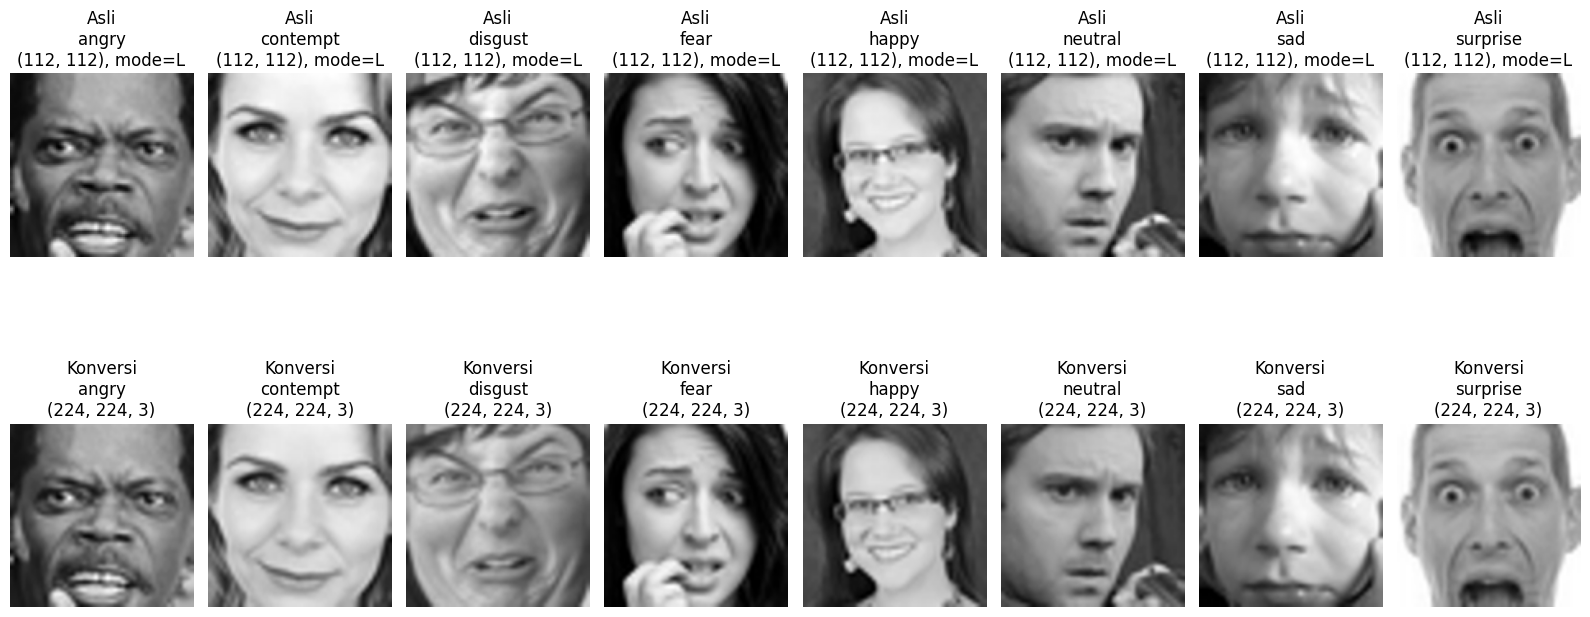

Gambar hasil contoh konversi disimpan ke:
C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\contoh_konversi_224x224x3.png


In [21]:
if "sample_df" not in globals():
    sample_rows = []

    for class_name in cfg.CLASS_NAMES:
        class_samples = df_detail_all[
            (df_detail_all["split"] == "training_non_augmented") &
            (df_detail_all["class"] == class_name) &
            (df_detail_all["is_valid"].astype(str).str.lower() == "true")
        ].copy()

        if len(class_samples) > 0:
            sample_rows.append(class_samples.iloc[0])

    sample_df = pd.DataFrame(sample_rows)

plt.figure(figsize=(16, 8))

for plot_index, (_, row) in enumerate(sample_df.iterrows()):
    image_path = row["path"]
    class_name = row["class"]

    original_img = Image.open(image_path)

    converted_array = utils.load_image_as_array(image_path)[0]

    plt.subplot(2, len(sample_df), plot_index + 1)
    plt.imshow(original_img, cmap="gray")
    plt.title(f"Asli\n{class_name}\n{original_img.size}, mode={original_img.mode}")
    plt.axis("off")

    plt.subplot(2, len(sample_df), plot_index + 1 + len(sample_df))
    plt.imshow(converted_array.astype("uint8"))
    plt.title(f"Konversi\n{class_name}\n{converted_array.shape}")
    plt.axis("off")

plt.tight_layout()

save_path = cfg.FIGURE_DIR / "contoh_konversi_224x224x3.png"
plt.savefig(save_path, dpi=300)
plt.show()

print("Gambar hasil contoh konversi disimpan ke:")
print(save_path)